## 1. Data Exploration and Preprocessing

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

warnings.filterwarnings('ignore', category=ConvergenceWarning)
sns.set_theme(style='whitegrid')

pd.set_option('display.max_columns', 12)

In [2]:
df = pd.read_csv('sonardataset.csv')
df.head()

,x_1,x_2,x_3,x_4,x_5,x_6,...,x_56,x_57,x_58,x_59,x_60,Y
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,...,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,...,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,...,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,...,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,...,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [3]:
print('Dataset shape:', df.shape)
print('Number of features:', df.shape[1] - 1)
print('Number of classes:', df['Y'].nunique())
print('Columns:', df.columns.tolist())

Dataset shape: (208, 61)
Number of features: 60
Number of classes: 2
Columns: ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7', 'x_8', 'x_9', 'x_10', 'x_11', 'x_12', 'x_13', 'x_14', 'x_15', 'x_16', 'x_17', 'x_18', 'x_19', 'x_20', 'x_21', 'x_22', 'x_23', 'x_24', 'x_25', 'x_26', 'x_27', 'x_28', 'x_29', 'x_30', 'x_31', 'x_32', 'x_33', 'x_34', 'x_35', 'x_36', 'x_37', 'x_38', 'x_39', 'x_40', 'x_41', 'x_42', 'x_43', 'x_44', 'x_45', 'x_46', 'x_47', 'x_48', 'x_49', 'x_50', 'x_51', 'x_52', 'x_53', 'x_54', 'x_55', 'x_56', 'x_57', 'x_58', 'x_59', 'x_60', 'Y']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x_1     208 non-null    float64
 1   x_2     208 non-null    float64
 2   x_3     208 non-null    float64
 3   x_4     208 non-null    float64
 4   x_5     208 non-null    float64
 5   x_6     208 non-null    float64
 6   x_7     208 non-null    float64
 7   x_8     208 non-null    float64
 8   x_9     208 non-null    float64
 9   x_10    208 non-null    float64
 10  x_11    208 non-null    float64
 11  x_12    208 non-null    float64
 12  x_13    208 non-null    float64
 13  x_14    208 non-null    float64
 14  x_15    208 non-null    float64
 15  x_16    208 non-null    float64
 16  x_17    208 non-null    float64
 17  x_18    208 non-null    float64
 18  x_19    208 non-null    float64
 19  x_20    208 non-null    float64
 20  x_21    208 non-null    float64
 21  x_22    208 non-null    float64
 22  x_

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
x_1,208.0,0.029164,0.022991,0.0015,0.013350,0.02280,0.035550,0.1371
x_2,208.0,0.038437,0.032960,0.0006,0.016450,0.03080,0.047950,0.2339
x_3,208.0,0.043832,0.038428,0.0015,0.018950,0.03430,0.057950,0.3059
x_4,208.0,0.053892,0.046528,0.0058,0.024375,0.04405,0.064500,0.4264
x_5,208.0,0.075202,0.055552,0.0067,0.038050,0.06250,0.100275,0.4010
x_6,208.0,0.104570,0.059105,0.0102,0.067025,0.09215,0.134125,0.3823
x_7,208.0,0.121747,0.061788,0.0033,0.080900,0.10695,0.154000,0.3729
x_8,208.0,0.134799,0.085152,0.0055,0.080425,0.11210,0.169600,0.4590
x_9,208.0,0.178003,0.118387,0.0075,0.097025,0.15225,0.233425,0.6828
x_10,208.0,0.208259,0.134416,0.0113,0.111275,0.18240,0.268700,0.7106


In [6]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Target values:', df['Y'].unique())

Missing values: 0
Duplicate rows: 0
Target values: ['R' 'M']


In [7]:
df['Y'].value_counts()

Y
M    111
R     97
Name: count, dtype: int64

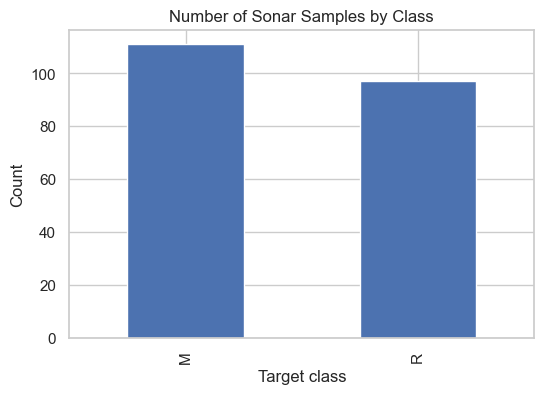

In [8]:
plt.figure(figsize=(6, 4))
df['Y'].value_counts().reindex(['M', 'R']).plot(kind='bar')
plt.title('Number of Sonar Samples by Class')
plt.xlabel('Target class')
plt.ylabel('Count')
plt.show()

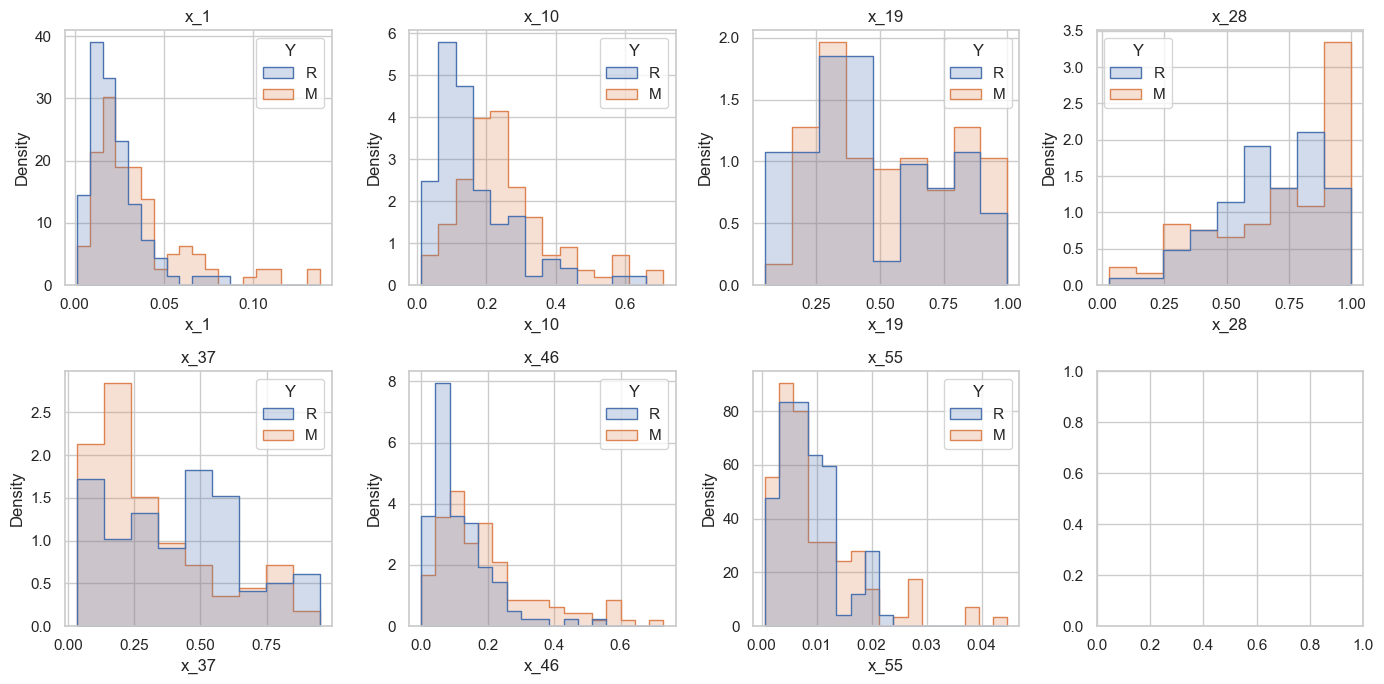

In [9]:
feature_cols = [f'x_{i}' for i in range(1, 61)]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.flat, feature_cols[::9][:8]):
    sns.histplot(data=df, x=col, hue='Y', element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

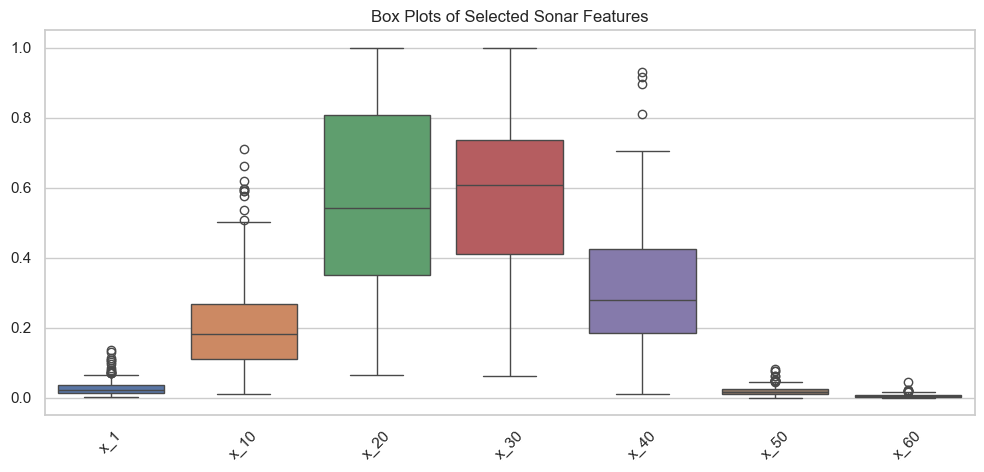

In [10]:
selected_features = ['x_1', 'x_10', 'x_20', 'x_30', 'x_40', 'x_50', 'x_60']
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[selected_features])
plt.title('Box Plots of Selected Sonar Features')
plt.xticks(rotation=45)
plt.show()

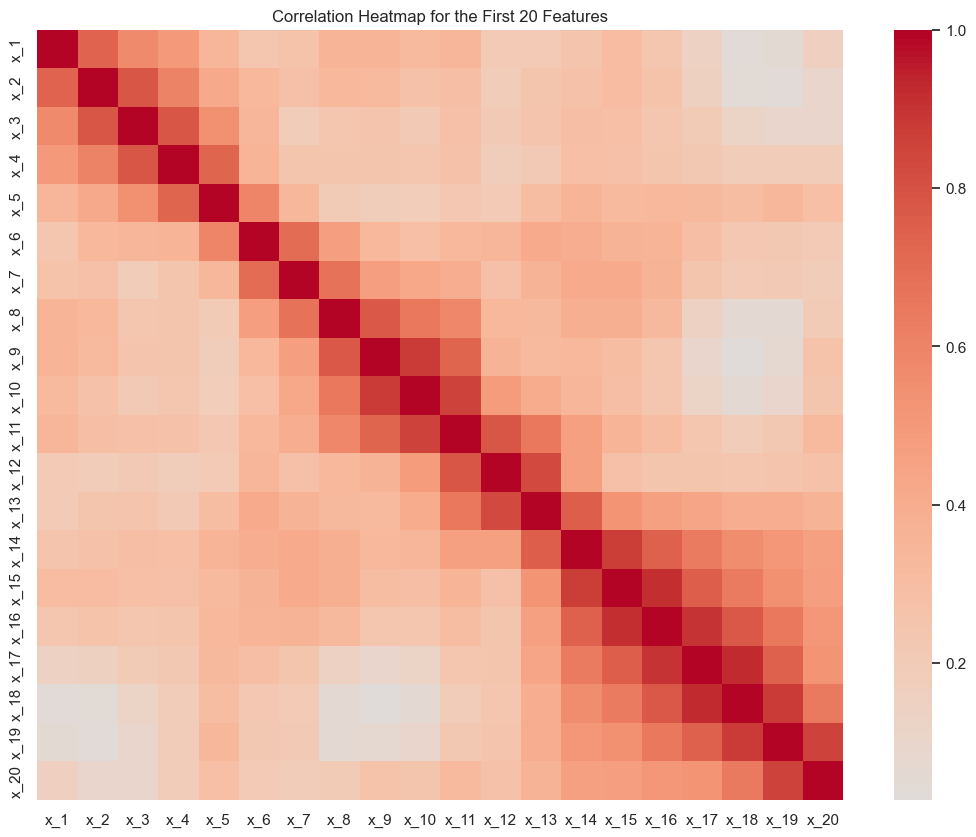

In [11]:
plt.figure(figsize=(13, 10))
sns.heatmap(df[feature_cols[:20]].corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap for the First 20 Features')
plt.show()

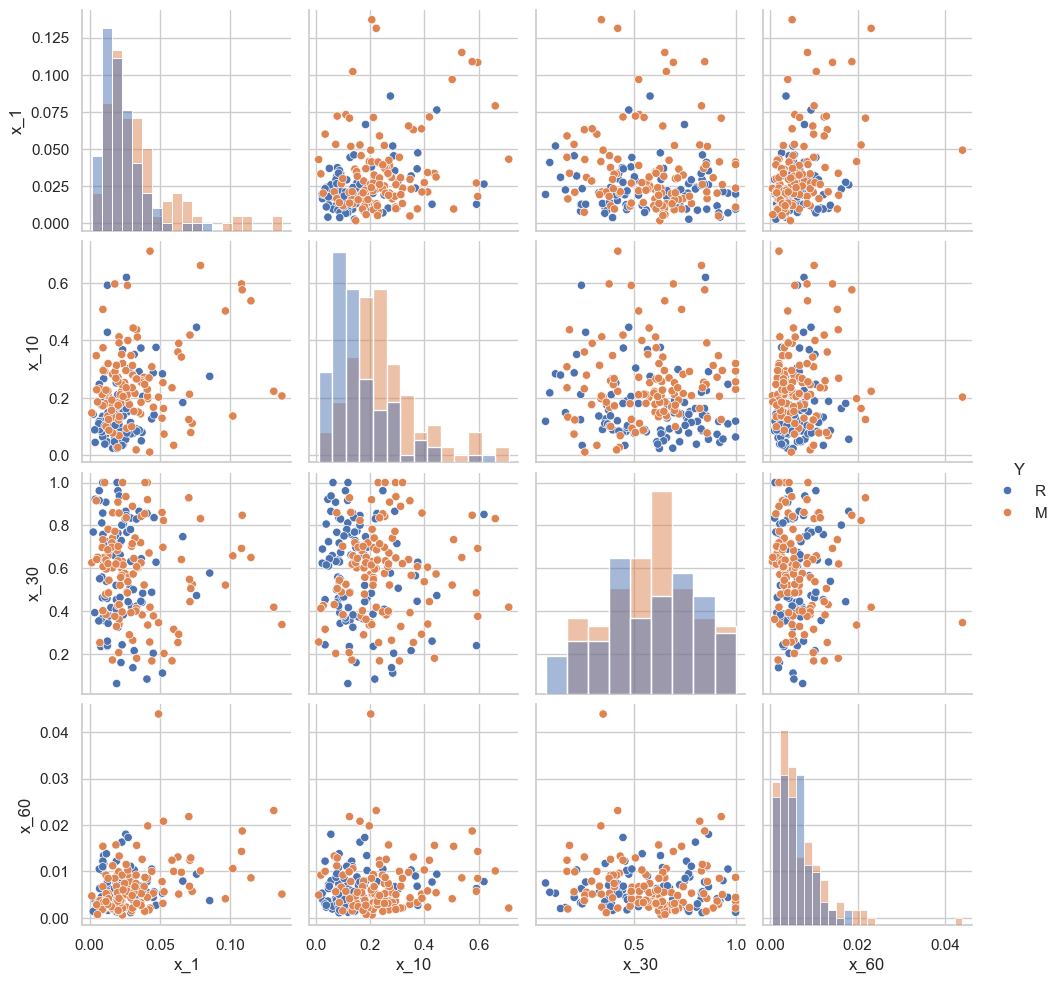

In [12]:
sns.pairplot(df[['x_1', 'x_10', 'x_30', 'x_60', 'Y']], hue='Y', diag_kind='hist')
plt.show()

## 2. Prepare the Data

In [13]:
X = df[feature_cols].copy()
y = df['Y'].map({'R': 0, 'M': 1})

print('Missing feature values:', X.isnull().sum().sum())
print('Missing target values:', y.isnull().sum())
print('Class counts:')
print(df['Y'].value_counts())

Missing feature values: 0
Missing target values: 0
Class counts:
Y
M    111
R     97
Name: count, dtype: int64


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])
print('Training class distribution:')
print(y_train.value_counts().rename(index={0: 'Rock', 1: 'Mine'}))
print('Testing class distribution:')
print(y_test.value_counts().rename(index={0: 'Rock', 1: 'Mine'}))

Training samples: 166
Testing samples: 42
Training class distribution:
Y
Mine    89
Rock    77
Name: count, dtype: int64
Testing class distribution:
Y
Mine    22
Rock    20
Name: count, dtype: int64


## 3. Build a Basic ANN

In [15]:
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=(10,),
        activation='relu',
        solver='adam',
        learning_rate_init=0.001,
        max_iter=1200,
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]

In [16]:
baseline_metrics = pd.DataFrame([{
    'Model': 'Basic ANN',
    'Accuracy': accuracy_score(y_test, baseline_pred),
    'Precision': precision_score(y_test, baseline_pred, zero_division=0),
    'Recall': recall_score(y_test, baseline_pred, zero_division=0),
    'F1-score': f1_score(y_test, baseline_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, baseline_prob)
}])
baseline_metrics

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Basic ANN,0.857143,0.863636,0.863636,0.863636,0.975


In [17]:
print(classification_report(
    y_test, baseline_pred, target_names=['Rock (R)', 'Mine (M)'], zero_division=0
))

              precision    recall  f1-score   support

    Rock (R)       0.85      0.85      0.85        20
    Mine (M)       0.86      0.86      0.86        22

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.86        42
weighted avg       0.86      0.86      0.86        42



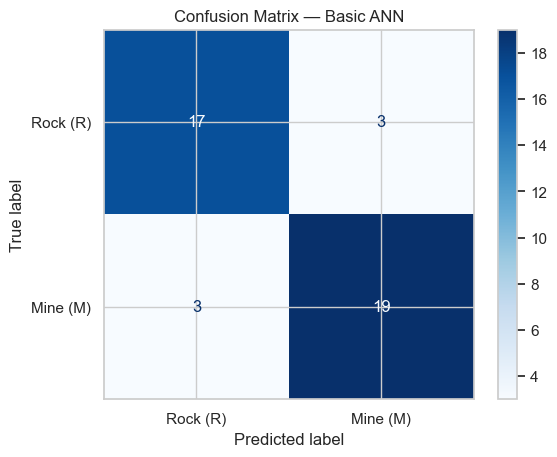

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, display_labels=['Rock (R)', 'Mine (M)'], cmap='Blues'
)
plt.title('Confusion Matrix — Basic ANN')
plt.show()

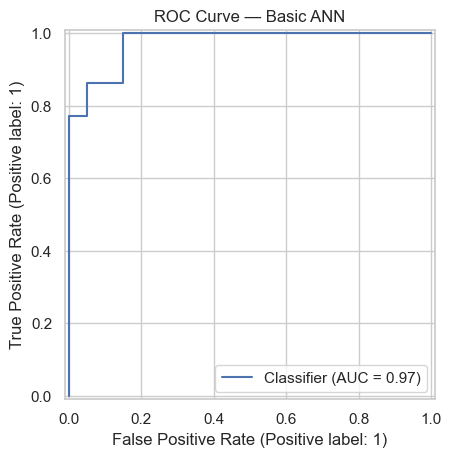

In [19]:
RocCurveDisplay.from_predictions(y_test, baseline_prob)
plt.title('ROC Curve — Basic ANN')
plt.show()

## 4. Hyperparameter Tuning

In [20]:
param_grid = {
    'mlp__hidden_layer_sizes': [(10,), (20,), (30, 15)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__alpha': [0.0001, 0.01],
    'mlp__learning_rate_init': [0.001, 0.01]
}

tuning_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        solver='adam',
        max_iter=1200,
        random_state=42
    ))
])

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=1,
    refit=True
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('mlp',
                                        MLPClassifier(max_iter=1200,
                                                      random_state=42))]),
             n_jobs=1,
             param_grid={'mlp__activation': ['relu', 'tanh'],
                         'mlp__alpha': [0.0001, 0.01],
                         'mlp__hidden_layer_sizes': [(10,), (20,), (30, 15)],
                         'mlp__learning_rate_init': [0.001, 0.01]},
             scoring='accuracy')

In [21]:
print('Best parameters:')
print(grid_search.best_params_)
print('Best mean cross-validation accuracy:', round(grid_search.best_score_, 4))

Best parameters:
{'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (30, 15), 'mlp__learning_rate_init': 0.01}
Best mean cross-validation accuracy: 0.8134


In [22]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results[['param_mlp__hidden_layer_sizes', 'param_mlp__activation', 'param_mlp__alpha', 'param_mlp__learning_rate_init', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').head(10)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__alpha,param_mlp__learning_rate_init,mean_test_score,std_test_score,rank_test_score
5,"(30, 15)",relu,0.0001,0.010,0.813369,0.028762,1
11,"(30, 15)",relu,0.0100,0.010,0.807308,0.035821,2
3,"(20,)",relu,0.0001,0.010,0.801426,0.044092,3
9,"(20,)",relu,0.0100,0.010,0.801426,0.044092,3
4,"(30, 15)",relu,0.0001,0.001,0.801070,0.036956,5
10,"(30, 15)",relu,0.0100,0.001,0.801070,0.036956,5
1,"(10,)",relu,0.0001,0.010,0.795544,0.057001,7
2,"(20,)",relu,0.0001,0.001,0.789483,0.055871,8
7,"(10,)",relu,0.0100,0.010,0.789483,0.048857,8
8,"(20,)",relu,0.0100,0.001,0.783422,0.057341,10


## 5. Evaluate the Tuned ANN

In [23]:
tuned_model = grid_search.best_estimator_
tuned_pred = tuned_model.predict(X_test)
tuned_prob = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = pd.DataFrame([{
    'Model': 'Tuned ANN',
    'Accuracy': accuracy_score(y_test, tuned_pred),
    'Precision': precision_score(y_test, tuned_pred, zero_division=0),
    'Recall': recall_score(y_test, tuned_pred, zero_division=0),
    'F1-score': f1_score(y_test, tuned_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, tuned_prob)
}])
tuned_metrics

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Tuned ANN,0.880952,0.904762,0.863636,0.883721,0.959091


In [24]:
print(classification_report(
    y_test, tuned_pred, target_names=['Rock (R)', 'Mine (M)'], zero_division=0
))

              precision    recall  f1-score   support

    Rock (R)       0.86      0.90      0.88        20
    Mine (M)       0.90      0.86      0.88        22

    accuracy                           0.88        42
   macro avg       0.88      0.88      0.88        42
weighted avg       0.88      0.88      0.88        42



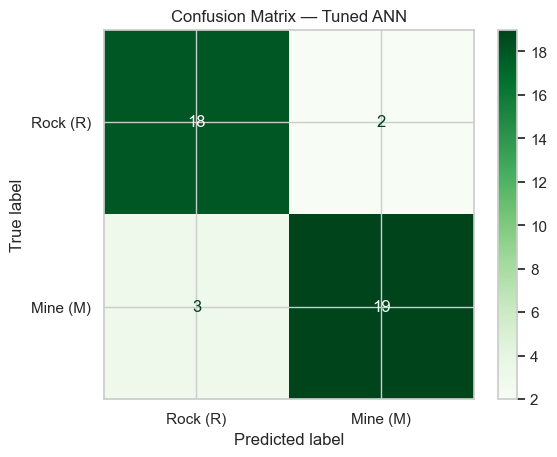

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=['Rock (R)', 'Mine (M)'], cmap='Greens'
)
plt.title('Confusion Matrix — Tuned ANN')
plt.show()

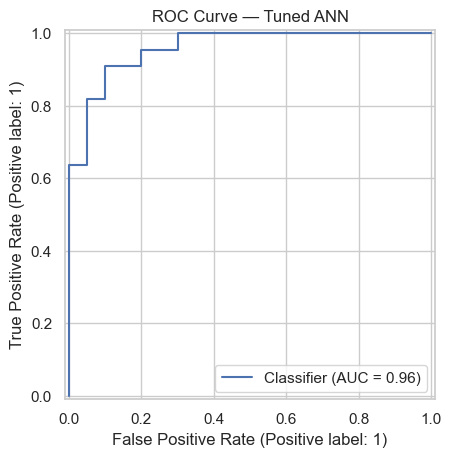

In [26]:
RocCurveDisplay.from_predictions(y_test, tuned_prob)
plt.title('ROC Curve — Tuned ANN')
plt.show()

In [27]:
comparison = pd.concat([baseline_metrics, tuned_metrics], ignore_index=True).set_index('Model')
comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Basic ANN,0.857143,0.863636,0.863636,0.863636,0.975000
Tuned ANN,0.880952,0.904762,0.863636,0.883721,0.959091


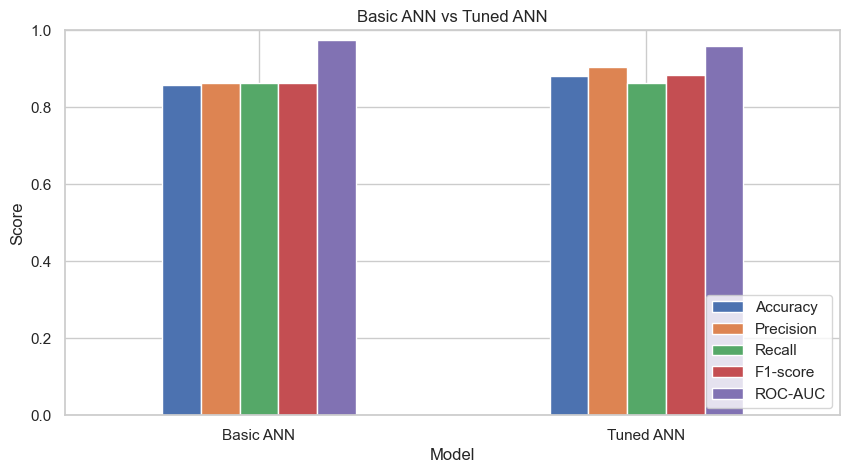

In [28]:
comparison[['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5), ylim=(0, 1))
plt.title('Basic ANN vs Tuned ANN')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [29]:
print('Basic ANN test accuracy:', round(baseline_metrics.loc[0, 'Accuracy'], 4))
print('Tuned ANN test accuracy:', round(tuned_metrics.loc[0, 'Accuracy'], 4))
print('Basic ANN F1-score:', round(baseline_metrics.loc[0, 'F1-score'], 4))
print('Tuned ANN F1-score:', round(tuned_metrics.loc[0, 'F1-score'], 4))

if tuned_metrics.loc[0, 'F1-score'] > baseline_metrics.loc[0, 'F1-score']:
    print('The tuned model achieved a higher F1-score on this test split.')
elif tuned_metrics.loc[0, 'F1-score'] < baseline_metrics.loc[0, 'F1-score']:
    print('The basic model achieved a higher F1-score on this test split.')
else:
    print('Both models achieved the same F1-score on this test split.')

Basic ANN test accuracy: 0.8571
Tuned ANN test accuracy: 0.881
Basic ANN F1-score: 0.8636
Tuned ANN F1-score: 0.8837
The tuned model achieved a higher F1-score on this test split.


## 6. Conclusion

The dataset contains 208 sonar observations, 60 numeric signal features, and two classes: mines and rocks. The features were standardized and the target was encoded before training. A basic neural network was evaluated first, then GridSearchCV was used to explore different network structures and learning settings. The comparison table and plots show whether tuning improved this particular train-test split. Results may vary with a different split because the dataset is relatively small, so cross-validation provides a useful additional check.